<a href="https://colab.research.google.com/github/LoLk1n-maker/recognize_text/blob/main/02_obuchenie_crnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Блокнот 2. Обучение модели распознавания CRNN + CTC

Обучаем **две одинаковые модели**, отличаются они только данными:
* `clean` — синтетика без искажений;
* `scan` — синтетика с искажениями сканирования.

Сравнение этих двух моделей показывает, что даёт моделирование искажений. Обе модели проверяются на синтетическом тесте со знакомыми и незнакомыми шрифтами. Проверка на реальных сканах и сравнение с Tesseract будут в блокноте 3.

**Нужен GPU:** Среда выполнения → Сменить среду выполнения → T4 GPU.
Обучение одной модели занимает примерно 15–25 минут. Прогресс сохраняется на Диск после каждой эпохи: если Colab отключится, просто запустите блокнот заново, и обучение продолжится с того же места.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time, random
ROOT = '/content/drive/MyDrive/tatar_ocr'
LOCAL = '/content/data'
for d in [f'{ROOT}/code', f'{ROOT}/models', f'{ROOT}/results', LOCAL]:
    os.makedirs(d, exist_ok=True)

import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '— GPU не подключён, обучение будет очень медленным!')

Mounted at /content/drive
Устройство: cuda Tesla T4


## 1. Модуль `crnn_ocr.py`

Модель, загрузка данных, декодирование и метрики. Файл сохраняется на Диск в `tatar_ocr/code/`, чтобы блокнот 3 использовал тот же код.

In [3]:
%%writefile /content/drive/MyDrive/tatar_ocr/code/crnn_ocr.py
# -*- coding: utf-8 -*-
"""crnn_ocr: модель CRNN + CTC для распознавания строк, загрузка данных и метрики.

Используется в блокнотах 2 (обучение) и 3 (тест на реальных сканах).
"""
import os, json, random, tarfile, collections
import numpy as np
import cv2

TT_SPECIAL_LOWER = "әөүҗңһ"


# ================================================================ алфавит
class Codec:
    """Перевод текста в номера классов и обратно. Класс 0 — «пусто» (blank) для CTC."""

    def __init__(self, alphabet):
        self.alphabet = alphabet
        self.idx = {ch: i + 1 for i, ch in enumerate(alphabet)}

    @property
    def num_classes(self):
        return len(self.alphabet) + 1

    def encode(self, text):
        return [self.idx[ch] for ch in text if ch in self.idx]

    def decode_greedy(self, seq):
        """Жадное декодирование CTC: склеиваем повторы, выбрасываем blank."""
        out, prev = [], 0
        for k in seq:
            if k != prev and k != 0:
                out.append(self.alphabet[k - 1])
            prev = k
        return "".join(out)


# ================================================================ данные
def extract_set(tar_path, local_dir):
    """Распаковывает набор с Диска на локальный диск Colab (один раз)."""
    name = os.path.basename(tar_path)[:-4]
    if not os.path.exists(f"{local_dir}/{name}/labels.tsv"):
        with tarfile.open(tar_path) as t:
            t.extractall(local_dir)
    return f"{local_dir}/{name}"


def load_set(folder, limit=None):
    """Читает все изображения набора в память. Возвращает (картинки, тексты)."""
    imgs, texts = [], []
    with open(f"{folder}/labels.tsv", encoding="utf-8") as f:
        rows = [r.split("\t") for r in f.read().splitlines() if r]
    for r in rows[:limit]:
        img = cv2.imread(f"{folder}/{r[0]}", cv2.IMREAD_GRAYSCALE)
        if img is not None:
            imgs.append(img)
            texts.append(r[1])
    return imgs, texts


def prepare_image(img, height=32, max_width=512):
    """Приводит изображение строки (в т. ч. вырезанной из скана) к входу модели."""
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = img.shape
    new_w = max(8, min(max_width, int(round(w * height / h))))
    return cv2.resize(img, (new_w, height), interpolation=cv2.INTER_AREA)


def make_batches(widths, batch_size, shuffle=True, rng=random):
    """Группирует строки похожей ширины в один батч, чтобы меньше было пустого заполнения."""
    idx = list(range(len(widths)))
    if shuffle:
        rng.shuffle(idx)
    chunk = batch_size * 50
    batches = []
    for s in range(0, len(idx), chunk):
        part = sorted(idx[s:s + chunk], key=lambda i: widths[i])
        batches += [part[j:j + batch_size] for j in range(0, len(part), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return batches


def collate(imgs, min_width=32):
    """Склеивает картинки разной ширины в один массив (N, 1, H, W) float32 в [-1, 1].
    Справа добивает повтором последнего столбца (фон). Возвращает массив и ширины."""
    W = max(min_width, max(im.shape[1] for im in imgs))
    W = (W + 3) // 4 * 4
    H = imgs[0].shape[0]
    out = np.empty((len(imgs), 1, H, W), np.float32)
    widths = []
    for k, im in enumerate(imgs):
        pad = np.pad(im, ((0, 0), (0, W - im.shape[1])), mode="edge")
        out[k, 0] = pad.astype(np.float32) / 127.5 - 1.0
        widths.append(im.shape[1])
    return out, widths


# ================================================================ модель
def build_crnn(num_classes, hidden=256, dropout=0.2):
    """CRNN: свёрточная часть (высота 32 -> 1, ширина / 4) + 2 слоя BiLSTM + линейный слой."""
    import torch.nn as nn

    def cbr(cin, cout, k=3, p=1):
        return [nn.Conv2d(cin, cout, k, padding=p, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

    class CRNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.cnn = nn.Sequential(
                *cbr(1, 64), nn.MaxPool2d(2, 2),                       # 16 x W/2
                *cbr(64, 128), nn.MaxPool2d(2, 2),                     # 8  x W/4
                *cbr(128, 256), *cbr(256, 256), nn.MaxPool2d((2, 1)),  # 4  x W/4
                *cbr(256, 512), *cbr(512, 512), nn.MaxPool2d((2, 1)),  # 2  x W/4
                *cbr(512, 512, k=(2, 1), p=0),                         # 1  x W/4
            )
            self.drop = nn.Dropout(dropout)
            self.rnn = nn.LSTM(512, hidden, num_layers=2, bidirectional=True,
                               batch_first=True, dropout=dropout)
            self.fc = nn.Linear(2 * hidden, num_classes)

        def forward(self, x):                      # x: (N, 1, 32, W)
            f = self.cnn(x).squeeze(2)             # (N, 512, W/4)
            f = self.drop(f.permute(0, 2, 1))      # (N, T, 512)
            f, _ = self.rnn(f)                     # (N, T, 2*hidden)
            return self.fc(self.drop(f))           # (N, T, num_classes)

    return CRNN()


def predict(model, imgs, codec, device, batch_size=128):
    """Распознаёт список картинок (уже высотой 32). Возвращает список строк."""
    import torch
    model.eval()
    preds = [None] * len(imgs)
    order = make_batches([im.shape[1] for im in imgs], batch_size, shuffle=False)
    with torch.no_grad():
        for b in order:
            x, widths = collate([imgs[i] for i in b])
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                out = model(torch.from_numpy(x).to(device))
            best = out.argmax(-1).cpu().numpy()
            for k, i in enumerate(b):
                preds[i] = codec.decode_greedy(best[k, : max(1, widths[k] // 4)])
    return preds


# ================================================================ метрики
def align(ref, hyp):
    """Выравнивание Левенштейна. Возвращает список пар (символ эталона или None,
    символ ответа или None): совпадение/замена, удаление (hyp=None), вставка (ref=None)."""
    n, m = len(ref), len(hyp)
    D = [list(range(m + 1))] + [[i] + [0] * m for i in range(1, n + 1)]
    for i in range(1, n + 1):
        Di, Dp, r = D[i], D[i - 1], ref[i - 1]
        for j in range(1, m + 1):
            Di[j] = min(Dp[j] + 1, Di[j - 1] + 1, Dp[j - 1] + (r != hyp[j - 1]))
    pairs, i, j = [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i][j] == D[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]):
            pairs.append((ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i][j] == D[i - 1][j] + 1:
            pairs.append((ref[i - 1], None)); i -= 1
        else:
            pairs.append((None, hyp[j - 1])); j -= 1
    return pairs[::-1], D[n][m]


def evaluate(refs, hyps):
    """CER, WER, точность строк и подробная статистика по буквам ә, ө, ү, җ, ң, һ."""
    ch_err = ch_tot = w_err = w_tot = exact = 0
    per = {c: collections.Counter() for c in TT_SPECIAL_LOWER}
    for r, h in zip(refs, hyps):
        pairs, d = align(r, h)
        ch_err += d; ch_tot += len(r)
        w_err += align(r.split(), h.split())[1]; w_tot += len(r.split())
        exact += r == h
        for a, b in pairs:
            if a is not None and a.lower() in per:
                c = per[a.lower()]
                c["total"] += 1
                if b is not None and b.lower() == a.lower():
                    c["ok"] += 1
                else:
                    c["→" + ("∅" if b is None else b.lower())] += 1
    tt_tot = sum(c["total"] for c in per.values())
    tt_ok = sum(c["ok"] for c in per.values())
    return {
        "CER": ch_err / max(1, ch_tot),
        "WER": w_err / max(1, w_tot),
        "строк без ошибок": exact / max(1, len(refs)),
        "ошибка на ә,ө,ү,җ,ң,һ": 1 - tt_ok / max(1, tt_tot),
        "по буквам": {c: dict(v) for c, v in per.items()},
    }


def letter_table(result):
    """Строки «буква: доля верных, частые замены» для вывода и для статьи."""
    rows = []
    for c, v in result["по буквам"].items():
        tot = v.get("total", 0)
        if not tot:
            continue
        subs = sorted(((k[1:], n) for k, n in v.items() if k.startswith("→")), key=lambda x: -x[1])[:3]
        rows.append((c, tot, v.get("ok", 0) / tot, ", ".join(f"{s} ({n})" for s, n in subs)))
    return rows

Writing /content/drive/MyDrive/tatar_ocr/code/crnn_ocr.py


In [4]:
sys.path.insert(0, f'{ROOT}/code')
import importlib, crnn_ocr as C
importlib.reload(C)

meta = json.load(open(f'{ROOT}/data/meta.json'))
codec = C.Codec(meta['alphabet'])
print('Классов на выходе модели (алфавит + blank):', codec.num_classes)
print('Наборы на Диске:', meta.get('sets'))

model = C.build_crnn(codec.num_classes)
print(f'Параметров в модели: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} млн')
x = torch.zeros(2, 1, 32, 200)
print('Вход', tuple(x.shape), '→ выход', tuple(model(x).shape), '(батч, шаги T = W/4, классы)')
del model

Классов на выходе модели (алфавит + blank): 108
Наборы на Диске: ['train_clean_50k', 'train_scan_50k', 'val_scan', 'test_scan_unseen_fonts']
Параметров в модели: 8.2 млн
Вход (2, 1, 32, 200) → выход (2, 50, 108) (батч, шаги T = W/4, классы)


## 2. Загрузка данных

Наборы распаковываются с Диска на локальный диск Colab и целиком читаются в память (50 тыс. строк — около 0,5 ГБ).

In [5]:
def find_set(prefix):
    names = [s for s in meta['sets'] if s.startswith(prefix)]
    assert names, f'Нет набора {prefix}* — сначала выполните раздел 6 блокнота 1'
    return names[0]

TRAIN_SETS = {'clean': find_set('train_clean'), 'scan': find_set('train_scan')}
EVAL_SETS = {'знакомые шрифты': 'val_scan', 'незнакомые шрифты': 'test_scan_unseen_fonts'}

data = {}
for name in list(TRAIN_SETS.values()) + list(EVAL_SETS.values()):
    t = time.time()
    folder = C.extract_set(f'{ROOT}/data/{name}.tar', LOCAL)
    data[name] = C.load_set(folder)
    print(f'{name}: {len(data[name][0])} строк, {time.time() - t:.0f} с')

train_clean_50k: 50000 строк, 19 с
train_scan_50k: 50000 строк, 23 с
val_scan: 5000 строк, 5 с
test_scan_unseen_fonts: 5000 строк, 5 с


## 3. Обучение

Параметры одинаковые для обеих моделей: оптимизатор AdamW, расписание скорости обучения OneCycle, смешанная точность (AMP), батч 64, 15 эпох.
После каждой эпохи считается CER на валидации (`val_scan`); лучшая по CER модель сохраняется как `models/<имя>_best.pt`.

In [6]:
EPOCHS = 15
BATCH = 64
LR = 1e-3

def train_model(tag, train_name, val_name='val_scan', epochs=EPOCHS, seed=0):
    random.seed(seed); torch.manual_seed(seed)
    imgs, texts = data[train_name]
    targets = [codec.encode(t) for t in texts]
    v_imgs, v_texts = data[val_name]

    model = C.build_crnn(codec.num_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    steps = len(C.make_batches([im.shape[1] for im in imgs], BATCH))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * steps, pct_start=0.15)
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    ctc = torch.nn.CTCLoss(blank=0, zero_infinity=True)

    last, best = f'{ROOT}/models/{tag}_last.pt', f'{ROOT}/models/{tag}_best.pt'
    hist, start, best_cer = [], 0, 1e9
    if os.path.exists(last):                                  # продолжение после обрыва
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
        hist, start, best_cer = ck['hist'], ck['epoch'] + 1, ck['best_cer']
        print(f'[{tag}] продолжаю с эпохи {start + 1}')
    if start >= epochs:
        print(f'[{tag}] уже обучена, лучший CER на валидации {best_cer:.2%}'); return hist

    rng = random.Random(seed)
    for _ in range(start):                                    # тот же порядок батчей, что и до обрыва
        C.make_batches([im.shape[1] for im in imgs], BATCH, rng=rng)
    for ep in range(start, epochs):
        model.train(); t = time.time(); tot = 0.0
        batches = C.make_batches([im.shape[1] for im in imgs], BATCH, rng=rng)
        for b in batches:
            x, widths = C.collate([imgs[i] for i in b])
            x = torch.from_numpy(x).to(device)
            tg = [targets[i] for i in b]
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
                out = model(x)                                 # (N, T, C)
            T = out.shape[1]
            log_probs = out.float().log_softmax(-1).permute(1, 0, 2)   # (T, N, C) для CTCLoss
            in_len = torch.tensor([min(T, max(1, w // 4)) for w in widths], dtype=torch.long)
            tg_len = torch.tensor([len(s) for s in tg], dtype=torch.long)
            tg_cat = torch.tensor([k for s in tg for k in s], dtype=torch.long, device=device)
            loss = ctc(log_probs, tg_cat, in_len, tg_len)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        preds = C.predict(model, v_imgs, codec, device)
        res = C.evaluate(v_texts, preds)
        hist.append({'epoch': ep + 1, 'loss': tot / len(batches), 'val_CER': res['CER'], 'val_WER': res['WER']})
        if res['CER'] < best_cer:
            best_cer = res['CER']
            torch.save({'model': model.state_dict(), 'alphabet': codec.alphabet, 'epoch': ep + 1}, best)
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                    'scaler': scaler.state_dict(), 'hist': hist, 'epoch': ep, 'best_cer': best_cer}, last)
        print(f'[{tag}] эпоха {ep + 1}/{epochs}: потеря {hist[-1]["loss"]:.3f}, '
              f'CER {res["CER"]:.2%}, WER {res["WER"]:.2%}, {time.time() - t:.0f} с')
    json.dump(hist, open(f'{ROOT}/results/history_{tag}.json', 'w'), indent=1)
    return hist

In [7]:
# Модель 1: обучение на синтетике БЕЗ искажений
hist_clean = train_model('clean', TRAIN_SETS['clean'])

/tmp/ipykernel_506/191750604.py:51: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


[clean] эпоха 1/15: потеря 2.551, CER 7.84%, WER 26.29%, 72 с
[clean] эпоха 2/15: потеря 0.044, CER 5.04%, WER 15.72%, 74 с
[clean] эпоха 3/15: потеря 0.019, CER 4.78%, WER 15.90%, 77 с
[clean] эпоха 4/15: потеря 0.011, CER 4.54%, WER 14.73%, 77 с
[clean] эпоха 5/15: потеря 0.008, CER 5.39%, WER 16.97%, 77 с
[clean] эпоха 6/15: потеря 0.006, CER 4.73%, WER 15.27%, 77 с
[clean] эпоха 7/15: потеря 0.006, CER 6.72%, WER 19.24%, 77 с
[clean] эпоха 8/15: потеря 0.003, CER 4.60%, WER 12.77%, 76 с
[clean] эпоха 9/15: потеря 0.002, CER 4.12%, WER 11.30%, 77 с
[clean] эпоха 10/15: потеря 0.001, CER 3.85%, WER 11.24%, 76 с
[clean] эпоха 11/15: потеря 0.001, CER 3.71%, WER 10.59%, 76 с
[clean] эпоха 12/15: потеря 0.000, CER 3.49%, WER 9.82%, 76 с
[clean] эпоха 13/15: потеря 0.000, CER 3.36%, WER 9.49%, 77 с
[clean] эпоха 14/15: потеря 0.000, CER 3.33%, WER 9.41%, 76 с
[clean] эпоха 15/15: потеря 0.000, CER 3.34%, WER 9.46%, 77 с


In [8]:
# Модель 2: обучение на синтетике С искажениями сканирования
hist_scan = train_model('scan', TRAIN_SETS['scan'])

[scan] эпоха 1/15: потеря 2.737, CER 4.83%, WER 21.66%, 78 с
[scan] эпоха 2/15: потеря 0.111, CER 1.99%, WER 8.03%, 77 с
[scan] эпоха 3/15: потеря 0.059, CER 1.47%, WER 5.55%, 77 с
[scan] эпоха 4/15: потеря 0.044, CER 1.37%, WER 5.09%, 78 с
[scan] эпоха 5/15: потеря 0.036, CER 1.82%, WER 7.80%, 77 с
[scan] эпоха 6/15: потеря 0.032, CER 1.02%, WER 3.53%, 77 с
[scan] эпоха 7/15: потеря 0.026, CER 1.00%, WER 3.45%, 78 с
[scan] эпоха 8/15: потеря 0.023, CER 0.95%, WER 3.11%, 77 с
[scan] эпоха 9/15: потеря 0.020, CER 0.89%, WER 2.97%, 77 с
[scan] эпоха 10/15: потеря 0.016, CER 0.83%, WER 2.50%, 77 с
[scan] эпоха 11/15: потеря 0.014, CER 0.79%, WER 2.35%, 77 с
[scan] эпоха 12/15: потеря 0.012, CER 0.79%, WER 2.38%, 77 с
[scan] эпоха 13/15: потеря 0.010, CER 0.74%, WER 2.19%, 77 с
[scan] эпоха 14/15: потеря 0.009, CER 0.75%, WER 2.14%, 76 с
[scan] эпоха 15/15: потеря 0.009, CER 0.74%, WER 2.19%, 77 с


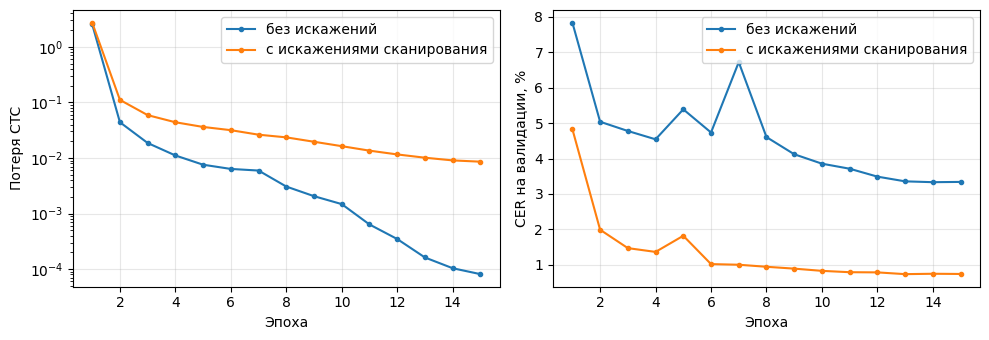

In [9]:
# Кривые обучения (рисунок для статьи, JPEG)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for tag, label in [('clean', 'без искажений'), ('scan', 'с искажениями сканирования')]:
    h = json.load(open(f'{ROOT}/results/history_{tag}.json'))
    ep = [r['epoch'] for r in h]
    ax[0].plot(ep, [r['loss'] for r in h], marker='o', ms=3, label=label)
    ax[1].plot(ep, [100 * r['val_CER'] for r in h], marker='o', ms=3, label=label)
ax[0].set_xlabel('Эпоха'); ax[0].set_ylabel('Потеря CTC'); ax[0].set_yscale('log')
ax[1].set_xlabel('Эпоха'); ax[1].set_ylabel('CER на валидации, %')
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(f'{ROOT}/fig_training.jpg', dpi=200); plt.show()

## 4. Оценка на синтетических тестах

Обе модели проверяются на строках из **тестовых** текстов: со знакомыми шрифтами (`val_scan`) и с отложенными шрифтами, которых модель не видела (`test_scan_unseen_fonts`).
Метрики: CER (доля ошибок по символам), WER (по словам), доля строк без ошибок и доля ошибок на буквах ә, ө, ү, җ, ң, һ.

In [10]:
import pandas as pd

def load_model(tag):
    ck = torch.load(f'{ROOT}/models/{tag}_best.pt', map_location=device, weights_only=False)
    m = C.build_crnn(len(ck['alphabet']) + 1).to(device)
    m.load_state_dict(ck['model']); m.eval()
    return m

results, all_preds = {}, {}
for tag in ['clean', 'scan']:
    m = load_model(tag)
    for set_label, set_name in EVAL_SETS.items():
        imgs, texts = data[set_name]
        preds = C.predict(m, imgs, codec, device)
        all_preds[(tag, set_label)] = preds
        results[(tag, set_label)] = C.evaluate(texts, preds)

rows = []
for (tag, set_label), r in results.items():
    rows.append({'модель': tag, 'тест': set_label,
                 **{k: round(100 * v, 2) for k, v in r.items() if k != 'по буквам'}})
table = pd.DataFrame(rows)
table.to_csv(f'{ROOT}/results/synth_results.csv', index=False)
json.dump({f'{a}|{b}': r for (a, b), r in results.items()}, open(f'{ROOT}/results/synth_results.json', 'w'),
          ensure_ascii=False, indent=1)
print('Все значения в процентах')
table

Все значения в процентах


,модель,тест,CER,WER,строк без ошибок,"ошибка на ә,ө,ү,җ,ң,һ"
0,clean,знакомые шрифты,3.33,9.41,80.20,2.85
1,clean,незнакомые шрифты,3.92,11.44,77.26,3.27
2,scan,знакомые шрифты,0.74,2.19,95.64,0.64
3,scan,незнакомые шрифты,1.08,4.45,90.66,1.17


In [11]:
# Ошибки на татарских буквах: доля верно распознанных и самые частые замены
for tag in ['clean', 'scan']:
    print(f'\nМодель {tag}, незнакомые шрифты:')
    for c, tot, acc, subs in C.letter_table(results[(tag, 'незнакомые шрифты')]):
        print(f'  {c}: встретилась {tot} раз, верно {acc:.1%}; замены: {subs or "—"}')


Модель clean, незнакомые шрифты:
  ә: встретилась 8960 раз, верно 96.7%; замены: ∅ (82), ө (72), - (14)
  ө: встретилась 1552 раз, верно 95.6%; замены: ∅ (21), в (12), ә (5)
  ү: встретилась 1441 раз, верно 97.6%; замены: ∅ (10), , (5), х (4)
  җ: встретилась 597 раз, верно 96.8%; замены: ∅ (9), - (2), х (2)
  ң: встретилась 1484 раз, верно 96.9%; замены: ∅ (19), н (4), и (3)
  һ: встретилась 967 раз, верно 97.2%; замены: ∅ (9), к (4),   (3)

Модель scan, незнакомые шрифты:
  ә: встретилась 8960 раз, верно 98.6%; замены: ө (60), е (24), ∅ (19)
  ө: встретилась 1552 раз, верно 99.2%; замены: т (2), ∅ (2), ә (2)
  ү: встретилась 1441 раз, верно 98.5%; замены: х (8), ∅ (4), у (4)
  җ: встретилась 597 раз, верно 98.8%; замены: ∅ (3), х (2), к (1)
  ң: встретилась 1484 раз, верно 99.6%; замены: н (3), ш (1),   (1)
  һ: встретилась 967 раз, верно 99.5%; замены:   (1), е (1), ∅ (1)


Строк с ошибками: 467 из 5000


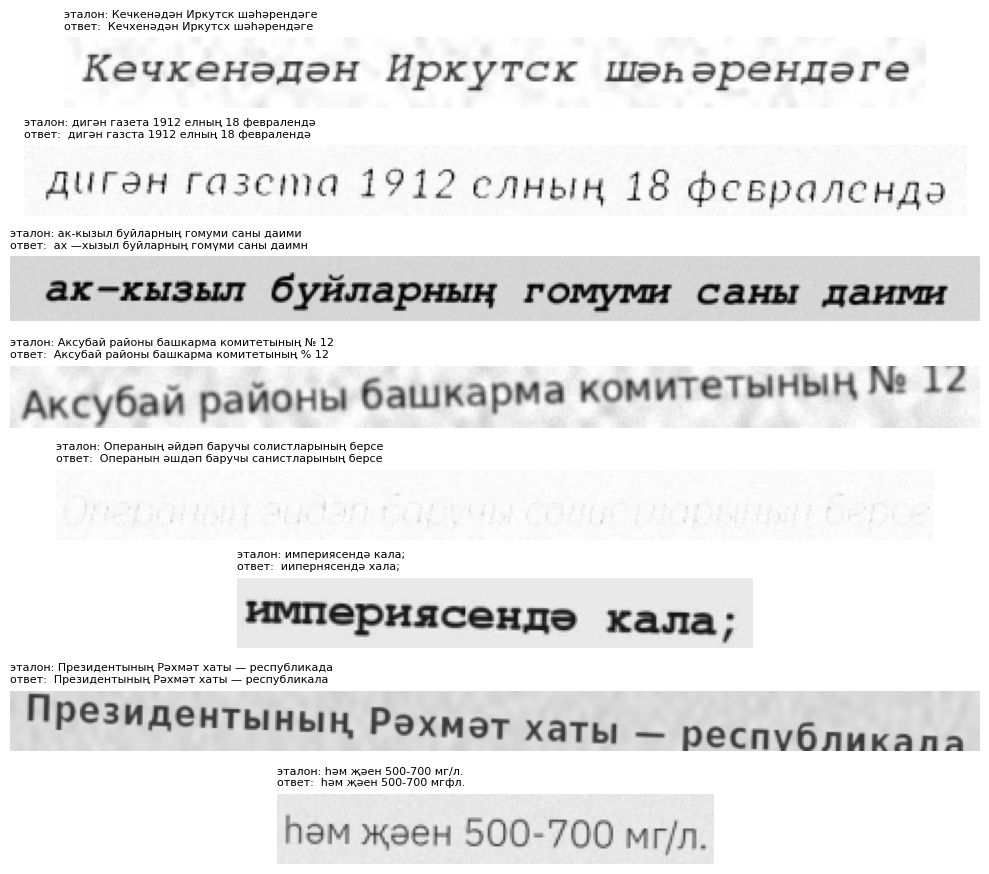

In [12]:
# Примеры ошибок модели scan на незнакомых шрифтах
imgs, texts = data['test_scan_unseen_fonts']
preds = all_preds[('scan', 'незнакомые шрифты')]
bad = [i for i in range(len(texts)) if preds[i] != texts[i]]
print(f'Строк с ошибками: {len(bad)} из {len(texts)}')
fig, axes = plt.subplots(min(8, len(bad)), 1, figsize=(10, 1.1 * min(8, len(bad))), squeeze=False)
for ax, i in zip(axes[:, 0], random.Random(1).sample(bad, min(8, len(bad)))):
    ax.imshow(imgs[i], cmap='gray', vmin=0, vmax=255); ax.set_axis_off()
    ax.set_title(f'эталон: {texts[i]}\nответ:  {preds[i]}', fontsize=8, loc='left')
plt.tight_layout(); plt.show()

## Что получилось

На Диске в `tatar_ocr/`:
* `models/clean_best.pt`, `models/scan_best.pt` — обученные модели;
* `results/history_*.json`, `fig_training.jpg` — кривые обучения (рисунок для статьи);
* `results/synth_results.csv` и `.json` — результаты на синтетических тестах.

Пришлите таблицу и вывод по буквам, и я впишу их в статью. Дальше блокнот 3: реальные сканы и сравнение с Tesseract.